In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as optimize

#Import function to obtain electron density:
#Doesn't work

vacuum_permittivity = 8.854e-12 # Permittivity of free space in Faradays over meters
e_charge = -1.602e-19 # Electron charge in Coulombs
e_mass = 9.10938356e-31 # Electron mass in Kilograms


def elec_dens(y):
    a = 4.451e3
    b = -200e3 # -356.08e3
    return a*y + b 

def ref_index(freq,elec_dens):
    delta_y = 1
    delta_x = 1 # units in kilometers
    total_pl = 2000
    total_y = total_pl + 100
    N = np.zeros(total_y) # Refraction index

    # First 80 km the refraction index will be 1 (air ref. index approx 1)

    Nf = 0.7

    for i in range(0,80,1):
        N[i] = 1    


    for i in range(80,total_pl,1):
        pl_freq = np.sqrt((elec_dens(i)*e_charge*e_charge)/(e_mass*vacuum_permittivity))
        #We need to avoid imaginary numbers:
        if ((pl_freq/freq)>1):
            N[i]=0
        else:
            N[i] = np.sqrt(1 - (pl_freq/freq)**2)

# N = np.sqrt(1 - (pl_freq/freq)**2)
    #print(N)
    return N


#And the grid distance:
delta_y=1

#We select the velocity of the light:
c=1

# NOW WE NEED TO DO ITERATIONS FOR DIFFERENT FREQUANCIES TO REACH THE END POINT:

destiny=500 #The x position we want to reach
reached=False #Change to True when reached the destiny

#while (!reached):
freq = 1e5# Radiofrequency from 50 kHz to 300 GHz, we choose 100 kHz   
n=ref_index(freq,elec_dens)
#for i in n:
#    print(i)

#y = np.linspace(0,399,1000)

#plt.plot(y,n)

def GetRay(angle,freq):
    n=ref_index(freq,elec_dens)
    #We choose the initial position and angle of the ray:
    ray=[[0,0]]
    #We just do iterations:
    step_t=0.5 #constant, time passing between iterations
    current_index=0 #To see in which pixel we are
    sum_h=0 #The sum of the height, to see if it passes to the next pixel

    #We track te iterations number too:
    i=0

    #A boolean to stop the iterations:
    boolean=True
    #angle_inicio=angle
    while boolean: 
        #The n index depends on the height:
        n0=n[current_index]
        x=step_t*c/n0*np.cos(angle)
        y=step_t*c/n0*np.sin(angle)
        #We need to see if we have reached the next height with this last step
        #To do so, we check if the sum is bigger than the grid size:
        '''
        print("sum of height: ",sum_h)
        print("refraction index: ",n0)
        print("angle: ", angle)
        print("current index: ", current_index)
        '''
        
        if (abs(sum_h+y)>=delta_y):
            k=1
            while((abs(sum_h+y)-k*delta_y)>delta_y):
                k+=1
            n1=np.mean(n[current_index+1:current_index+k+1])
            current_index+=k #We go to the next grid
            #See if changes refraction index:
            if (n1==n0):
                sum_h+= y - delta_y #Goes to next cell normal
                ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
            else:
                #Snell law to calculate new angle.
                #CAUTION: Snell angle is taken from the normal and ours is from the horizontal axis:
                #We need to do sin(90-theta)=cos(theta)
                angle0=angle
                if (n1 == 0):
                    print("The wave went through the Plasma. \n")
                    boolean = False
                #CAREFUL: arcsin input has to be between -1 and 1. If it exceedes, add/substract 1
                elif ((abs(n0*np.cos(angle0))/n1)>=1):
                    #There has been an internal reflection, the wave can't pass. We stop
                    boolean=False
                else:
                    angle=(np.pi/2.)-np.arcsin((n0*np.cos(angle0))/n1)
                    #Now we need to calculate the height.
                    #It divides into two heights:
                    #1)height in previous cell: delta_y-sum_h
                    #2)height in new cell with new angle and n:
                    y1=(delta_y-sum_h)
                    y2=(c/n1)*np.sin(angle)*(step_t-((delta_y-sum_h)/(c*np.sin(angle0)/n0)))
                    y=y1+y2
                    #The y can be negative, but the x is always positive (it moves forward)
                    x=abs(y1/np.tan(angle0))+abs(y2/np.tan(angle))
                    #We put the sum back to current height in next cell, to count again:
                    sum_h=y2 
                    #We add the new total position of our ray:
                    ray.append([ray[i-1][0]+x,ray[i-1][1]+y])

        else:
            #If it doesn't jump to next cell the ray will travel normally:
            ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
            sum_h+=y
            
        #Next iteration:
        i+=1
        # print(boolean)
    return ray
def GetLastPosition(angle,freq):
    ray=GetRay(angle,freq)
    return (2*ray[-1][0])

ranges = open("Range_freq_angle.txt", "w")

ranges.write("Frequency \t Angle \t Distance \n \n")

for i in range(21):
    freq=(1+(i/10))*1e5
    maximo=0
    max_angle = 0
    print( "\n","At frequency:", freq)
    for j in range(14):
        
        angle=(10+j*5)*np.pi/180
        dist = GetLastPosition(angle,freq)
        print("At angle:", angle*180/np.pi)
        print(dist)
        ranges.write(str(freq) + '\t')
        ranges.write(str(angle) + '\t')
        ranges.write(str(dist) + '\n')
        # To get the max, angle and distance. Just to check for us
        if (GetLastPosition(angle,freq)>maximo):
            maximo=GetLastPosition(angle,freq)
            max_angle = angle*180/np.pi
        
        print("And maximum occurs at: ",maximo," at angle: ", max_angle)


 At frequency: 100000.0
At angle: 10.0
453.99637413862683
And maximum occurs at:  453.99637413862683  at angle:  10.0
At angle: 14.999999999999998
490.87032152954873
And maximum occurs at:  490.87032152954873  at angle:  14.999999999999998
At angle: 20.0
549.3958592362582
And maximum occurs at:  549.3958592362582  at angle:  20.0
At angle: 25.0
714.0723913683844
And maximum occurs at:  714.0723913683844  at angle:  25.0
At angle: 29.999999999999996
676.0907552143815
And maximum occurs at:  714.0723913683844  at angle:  25.0
At angle: 35.0
735.2273555913952
And maximum occurs at:  735.2273555913952  at angle:  35.0
At angle: 40.0
728.7069051838216
And maximum occurs at:  735.2273555913952  at angle:  35.0
At angle: 45.0
724.0436631212046
And maximum occurs at:  735.2273555913952  at angle:  35.0
At angle: 50.0
735.6644591396059
And maximum occurs at:  735.6644591396059  at angle:  50.0
At angle: 55.0
679.41368889744
And maximum occurs at:  735.6644591396059  at angle:  50.0
At angle: 5

'\n# ONCE WE HAVE THE CORRECT RAY WE DO AN ANDRES\nandres=[]\nfor j in range (len(ray)):\n    andres.append([distance-ray[j][0],ray[j][1]])\nx_axis2=[]\ny_axis2=[]\nfor j in range(len(andres)):\n    x_axis2.append(andres[j][0])\n    y_axis2.append(andres[j][1])\n#print(y_axis)\nplt.scatter(x_axis2,y_axis2)\n'

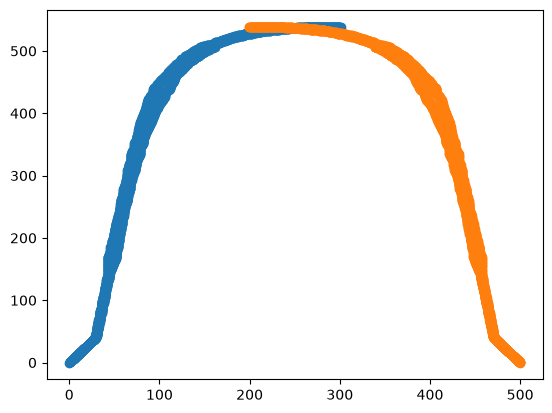

In [17]:
# Now We have the right angle:
# right_angle=optimize.newton(GetLastPosition,[(60*np.pi/180), freq],tol=1.e-2)
# print(right_angle*180/np.pi)

ranges.close()

x_axis=[]
y_axis=[]

selected_angle, selected_freq = 45, 1.5e5

ray = GetRay(selected_angle*180/np.pi,selected_freq)

for j in range(len(ray)):
    x_axis.append(-ray[j][0])
    y_axis.append(ray[j][1])
#print(y_axis)

plt.scatter(x_axis,y_axis)

# ONCE WE HAVE THE CORRECT RAY WE DO AN ANDRES
andres=[]
for j in range (len(ray)):
    andres.append([destiny+ray[j][0],ray[j][1]])
x_axis2=[]
y_axis2=[]
for j in range(len(andres)):
    x_axis2.append(andres[j][0])
    y_axis2.append(andres[j][1])
#print(y_axis)
plt.scatter(x_axis2,y_axis2)
'''
for j in range(len(ray)-2):
    x=[ray[j][0],ray[j+2][0]]
    y=[ray[j][1],ray[j+2][1]]
    #plt.plot(x,y)
x_axis=[]
y_axis=[]
for j in range(len(ray)):
    x_axis.append(ray[j][0])
    y_axis.append(ray[j][1])
#print(y_axis)

plt.scatter(x_axis,y_axis)
'''

'''
Imagine that we want to reach the point 400.
We put andres at point (400,0) at the beginning
and we do a normal ray but in the opppsite direction.
as the paths of the wave are reversible, the y value
will be the same and the x will be the mirror:
'''

'''
# ONCE WE HAVE THE CORRECT RAY WE DO AN ANDRES
andres=[]
for j in range (len(ray)):
    andres.append([distance-ray[j][0],ray[j][1]])
x_axis2=[]
y_axis2=[]
for j in range(len(andres)):
    x_axis2.append(andres[j][0])
    y_axis2.append(andres[j][1])
#print(y_axis)
plt.scatter(x_axis2,y_axis2)
'''